# Traffic Sign Visibility Audit (GTSRB)
Rule-based audit with NumPy, pandas, Matplotlib and OpenCV. **No deep learning.** Flags are triage aids, not safety verdicts. Run all cells from top to bottom.

In [1]:
import sys, logging
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
import traffic_sign_audit as tsa
from report import write_report
logging.basicConfig(level=logging.INFO, format='%(levelname)s: %(message)s')
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 40)

## 1. Configuration (project choices)

In [2]:
DATA_ROOT = ROOT / 'data' / 'GTSRB'      # change to data/GTSRB_demo only for smoke tests
SELECTED = [0, 1, 13, 14, 17, 25]         # >= 5 classes
audit = tsa.TrafficSignAudit(DATA_ROOT, ROOT / 'outputs', SELECTED, max_per_class=500, seed=42)

## 2. Load and inspect the FULL annotations (full-dataset counts)

In [3]:
ann = audit.load_annotations()
display(ann.head())
print('Rows:', audit.quality['n_rows'], '| classes:', audit.quality['n_classes'])
print('dtypes:', audit.quality['dtypes'])
pd.Series({k: v for k, v in audit.quality.items() if k.startswith('n_') or k == 'missing_values'})

INFO: Annotations: 39209 rows, 43 classes


,annotation_id,Filename,Width,Height,Roi.X1,Roi.Y1,Roi.X2,Roi.Y2,ClassId,source_csv,source_row,image_path,image_exists,class_valid,dims_valid,roi_valid
0,0,/code/Train/20/00020_00000_00000.png,27.0,26.0,5.0,5.0,22.0,20.0,20,Train.csv,2,Train/20/00020_00000_00000.png,True,True,True,True
1,1,/code/Train/20/00020_00000_00001.png,28.0,27.0,5.0,6.0,23.0,22.0,20,Train.csv,3,Train/20/00020_00000_00001.png,True,True,True,True
2,2,/code/Train/20/00020_00000_00002.png,29.0,26.0,6.0,5.0,24.0,21.0,20,Train.csv,4,Train/20/00020_00000_00002.png,True,True,True,True
3,3,/code/Train/20/00020_00000_00003.png,28.0,27.0,5.0,6.0,23.0,22.0,20,Train.csv,5,Train/20/00020_00000_00003.png,True,True,True,True
4,4,/code/Train/20/00020_00000_00004.png,28.0,26.0,5.0,5.0,23.0,21.0,20,Train.csv,6,Train/20/00020_00000_00004.png,True,True,True,True


Rows: 39209 | classes: 43
dtypes: {'Filename': 'str', 'Width': 'float64', 'Height': 'float64', 'Roi.X1': 'float64', 'Roi.Y1': 'float64', 'Roi.X2': 'float64', 'Roi.Y2': 'float64', 'ClassId': 'Int64'}


n_rows                                                                 39209
n_csv_files                                                                1
n_classes                                                                 43
missing_values             {'Filename': 0, 'Width': 0, 'Height': 0, 'Roi....
n_duplicate_rows                                                           0
n_duplicate_image_paths                                                    0
n_invalid_image_paths                                                      0
n_invalid_class_id                                                         0
n_invalid_dimensions                                                       0
n_invalid_or_absent_roi                                                    0
dtype: object

In [4]:
counts = audit.class_counts()
counts.sort_values('n_full', ascending=False).head(43)

,class_id,n_full,class_name,selected
2,2,2250,Speed limit 50,False
1,1,2220,Speed limit 30,True
13,13,2160,Yield,True
12,12,2100,Priority road,False
38,38,2070,Keep right,False
10,10,2010,No passing (>3.5 t),False
4,4,1980,Speed limit 70,False
5,5,1860,Speed limit 80,False
25,25,1500,Road work,True
9,9,1470,No passing,False


## 3. Stratified sample, OpenCV features, tidy table

In [5]:
audit.select_sample()
feats = audit.extract_features()
print('Skipped:', dict(audit.skipped))
pd.DataFrame(audit.exclusions).head(20)

INFO: Features extracted for 2710 images (skipped: {})


Skipped: {}


,stage,item,reason
0,annotation_file,Train.csv,image paths contained a foreign prefix; the fi...


In [6]:
feats[['image_path','class_id','width','height','brightness_gray','contrast_gray','sharpness_lapvar','roi_valid']].head()

,image_path,class_id,width,height,brightness_gray,contrast_gray,sharpness_lapvar,roi_valid
0,Train/0/00000_00000_00000.png,0,29,30,127.378161,45.603849,4623.091140,True
1,Train/0/00000_00000_00001.png,0,30,30,128.307778,45.720719,5136.776310,True
2,Train/0/00000_00000_00002.png,0,30,30,126.656667,44.542700,4411.520217,True
3,Train/0/00000_00000_00003.png,0,31,31,125.161290,45.182368,5041.459462,True
4,Train/0/00000_00000_00004.png,0,30,32,129.823958,47.292103,5492.097760,True


## 4. Review-priority rule (NumPy) and sensitivity check

In [7]:
audit.assign_review_priority()
audit.summarize()
print(audit.thresholds)
audit.sensitivity

{'low_pct': 10.0, 'high_pct': 90.0, 'brightness_low': 36.88527307387602, 'brightness_high': 165.12172036572417, 'contrast_low': 15.236608419541785, 'sharpness_low': 177.28289721501582, 'min_side_low': 30.0}


,scenario,low_pct,high_pct,brightness_low,brightness_high,contrast_low,sharpness_low,min_side_low,n_flagged,pct_flagged
0,baseline_P10_P90,10.0,90.0,36.89,165.12,15.24,177.28,30.0,848,31.29
1,strict_P5_P95,5.0,95.0,24.05,179.56,10.39,83.41,28.0,420,15.50
2,lenient_P20_P80,20.0,80.0,55.43,136.94,25.97,401.84,33.0,1568,57.86


In [8]:
print('Flagged overall:', int(audit.features['review_flag'].sum()), 'of', len(audit.features))
audit.flag_rate_wide

Flagged overall: 848 of 2710


scenario,baseline_P10_P90,strict_P5_P95,lenient_P20_P80
class_id,,,
0,23.33,3.33,42.38
1,22.40,11.00,53.00
13,40.00,20.80,67.00
14,20.00,8.60,44.60
17,43.40,22.60,70.00
25,34.00,19.60,61.20


## 5. pandas summaries

In [9]:
display(audit.class_summary)
display(audit.effect_sizes)
display(audit.rank_table)
display(audit.correlations)
audit.roi_comparison

,class_name,n_images,width_mean,width_median,width_std,height_mean,height_median,height_std,min_side_px_mean,min_side_px_median,min_side_px_std,brightness_gray_mean,brightness_gray_median,brightness_gray_std,contrast_gray_mean,contrast_gray_median,contrast_gray_std,sharpness_lapvar_mean,sharpness_lapvar_median,sharpness_lapvar_std
class_id,,,,,,,,,,,,,,,,,,,,
0,Speed limit 20,210,52.91,45.5,23.10,53.86,45.0,24.14,52.42,45.0,23.13,122.70,122.60,28.34,52.13,51.09,17.38,2444.10,1668.88,1929.27
1,Speed limit 30,500,52.50,48.0,21.01,53.56,48.0,21.68,52.07,48.0,20.82,109.47,110.34,44.17,50.62,49.36,21.53,2280.53,1664.43,1992.56
13,Yield,500,58.96,51.0,27.35,55.55,49.0,24.78,54.55,47.0,24.22,97.38,92.18,51.44,46.95,46.64,26.03,1792.81,1001.47,2117.47
14,Stop,500,66.15,56.0,34.28,68.22,57.0,34.89,65.74,55.0,33.84,111.86,107.33,42.48,57.18,60.02,19.14,2227.00,1713.14,1664.35
17,No entry,500,37.66,34.0,11.57,39.99,37.0,11.53,37.46,34.0,11.41,77.74,75.64,41.04,42.55,42.04,22.66,1738.01,1170.77,1710.46
25,Road work,500,63.56,52.0,33.16,59.75,50.0,30.65,59.37,50.0,30.23,82.60,71.10,48.03,39.69,37.29,22.89,1418.38,863.52,1467.80


,feature,eta_squared,effect_size
0,min_side_px,0.115,medium
1,brightness_gray,0.103,medium
2,contrast_gray,0.069,medium
3,log10_sharpness,0.076,medium


scenario,baseline_P10_P90,strict_P5_P95,lenient_P20_P80
class_id,,,
0,4,6,6
1,5,4,4
13,2,2,2
14,6,5,5
17,1,1,1
25,3,3,3


,sharpness_lapvar,contrast_gray,brightness_gray
sharpness_lapvar,1.000,0.679,0.626
contrast_gray,0.679,1.000,0.776
brightness_gray,0.626,0.776,1.000


,feature,mean_full,mean_roi,mean_abs_diff,spearman_full_vs_roi
0,brightness_gray,99.065,101.987,10.544,0.956
1,contrast_gray,46.341,44.480,4.255,0.959
2,sharpness_lapvar,2063.826,2705.587,785.914,0.952


## 6. Figures

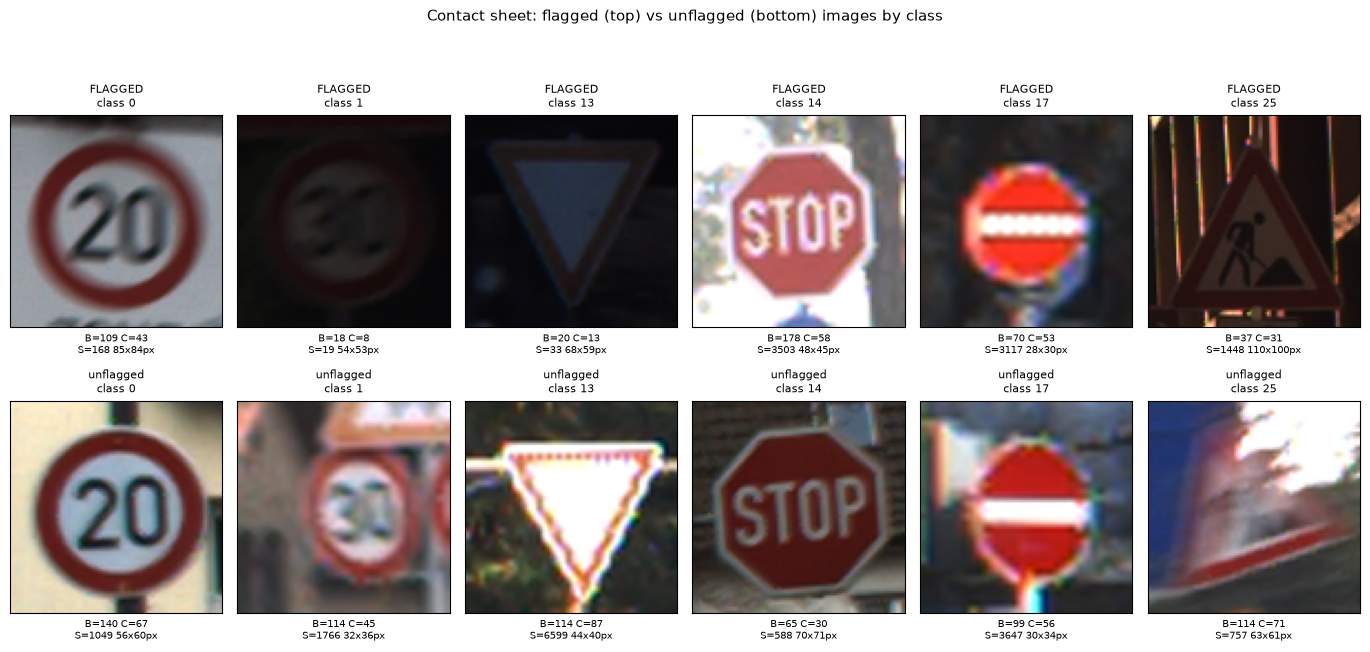

WindowsPath('C:/Users/Public/traffic-sign-audit/outputs/figures/fig01_contact_sheet.png')

In [10]:
audit.plot_contact_sheet(show=True)

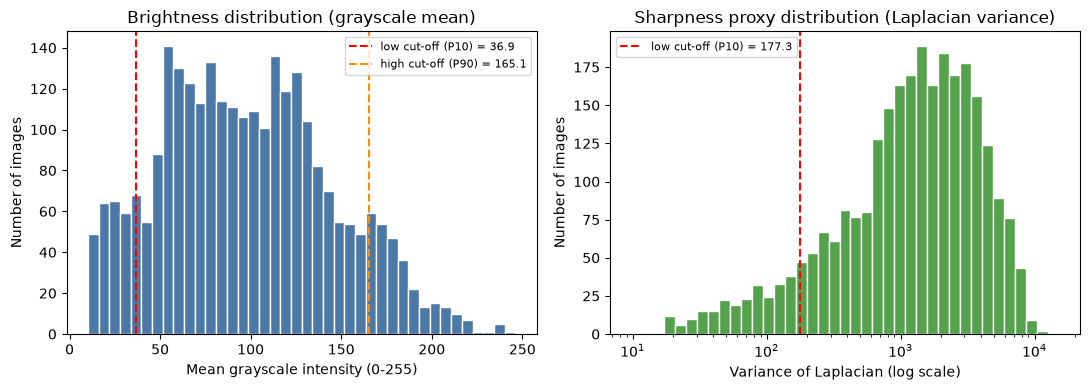

WindowsPath('C:/Users/Public/traffic-sign-audit/outputs/figures/fig02_distributions_with_cutoffs.png')

In [11]:
audit.plot_distributions(show=True)

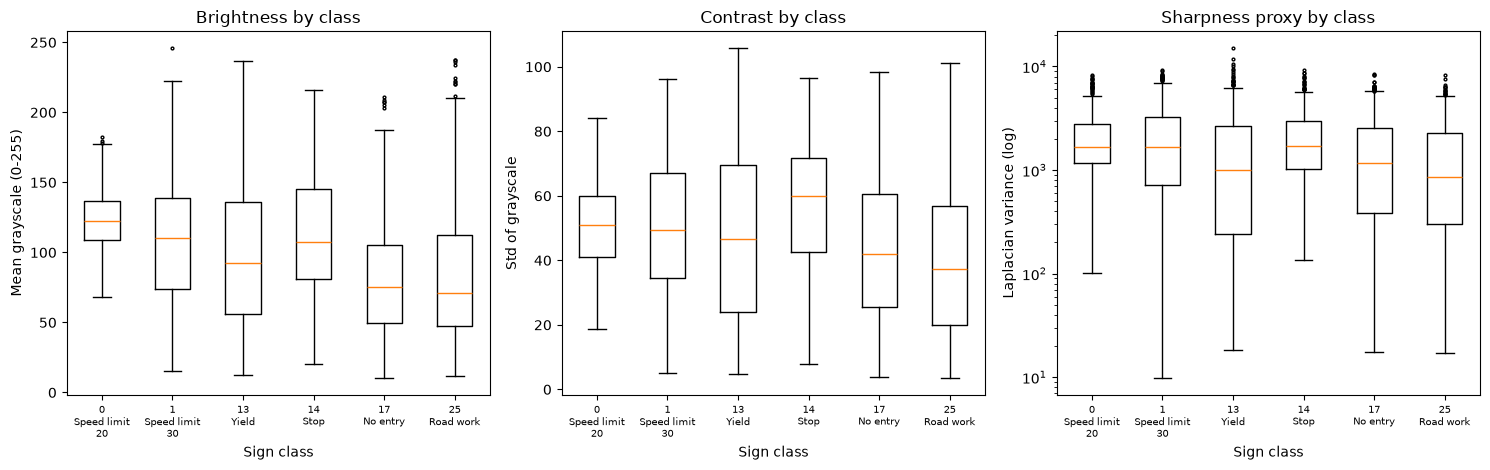

WindowsPath('C:/Users/Public/traffic-sign-audit/outputs/figures/fig03_boxplots_by_class.png')

In [12]:
audit.plot_boxplots(show=True)

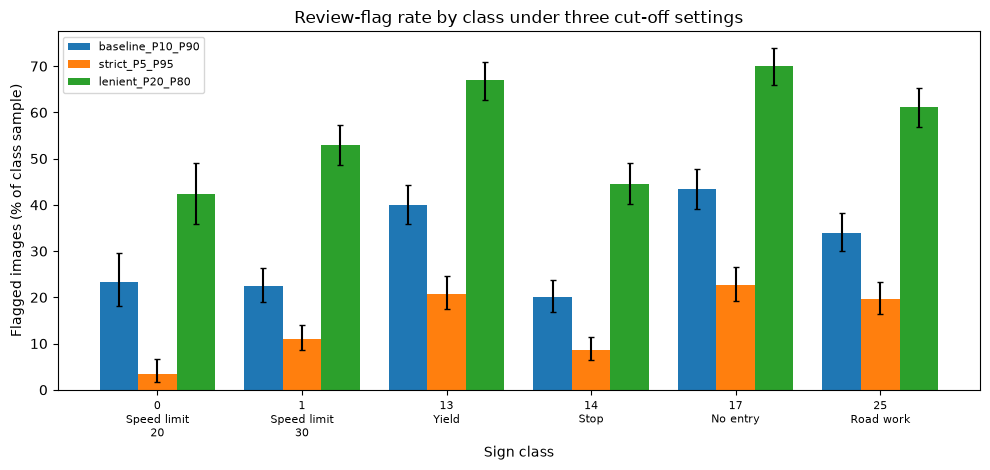

WindowsPath('C:/Users/Public/traffic-sign-audit/outputs/figures/fig04_flag_rate_by_class.png')

In [13]:
audit.plot_flag_rates(show=True)

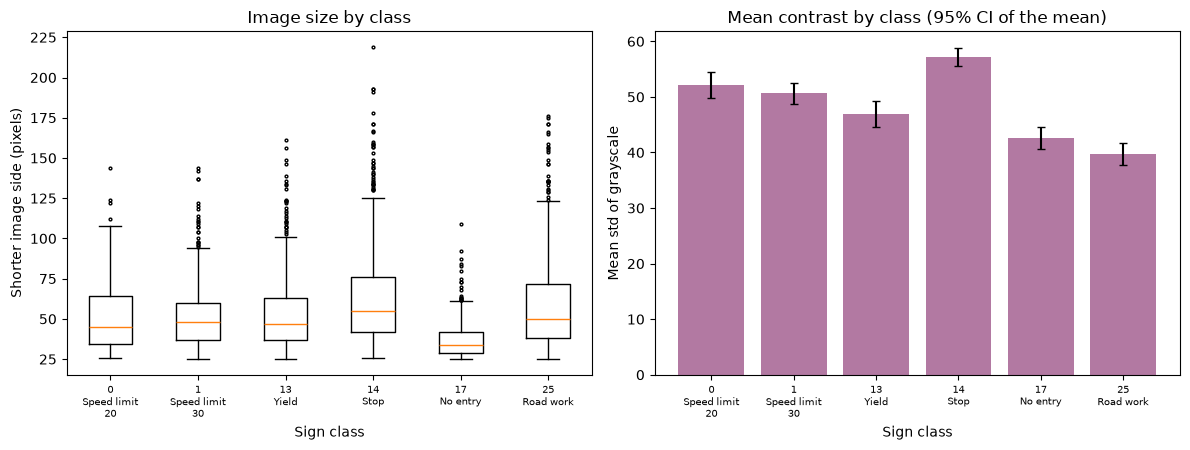

WindowsPath('C:/Users/Public/traffic-sign-audit/outputs/figures/fig05_size_and_contrast_by_class.png')

In [14]:
audit.plot_size_contrast(show=True)

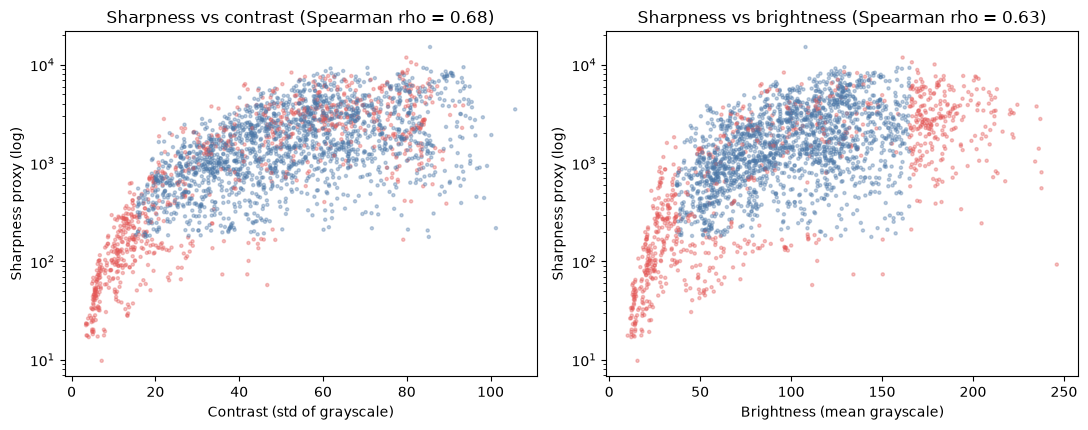

WindowsPath('C:/Users/Public/traffic-sign-audit/outputs/figures/fig06_sharpness_vs_contrast_brightness.png')

In [15]:
audit.plot_relationships(show=True)

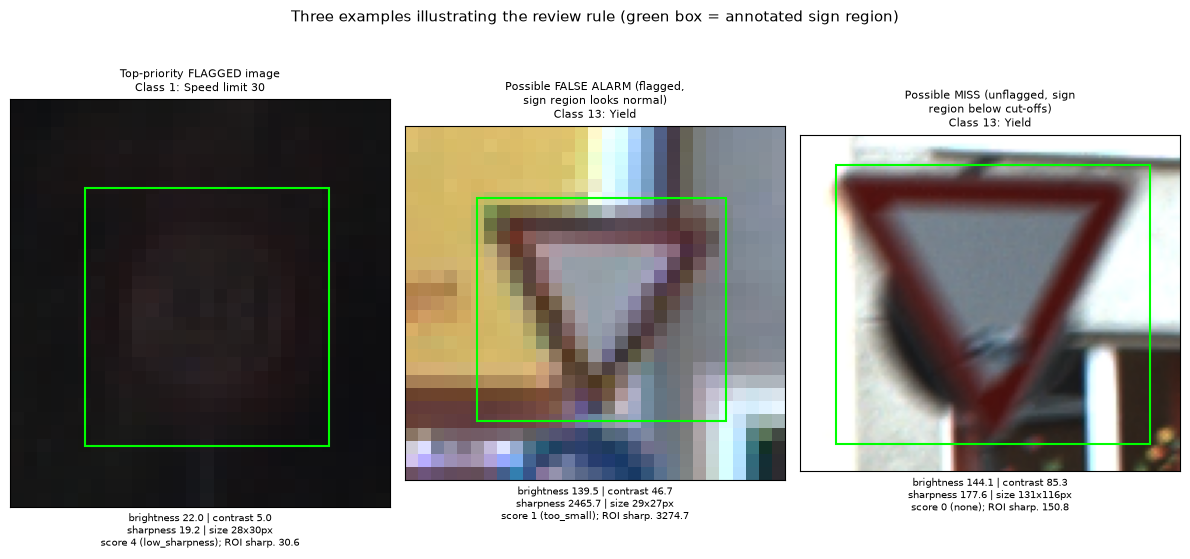

WindowsPath('C:/Users/Public/traffic-sign-audit/outputs/figures/fig07_three_examples.png')

In [16]:
audit.plot_examples(show=True)

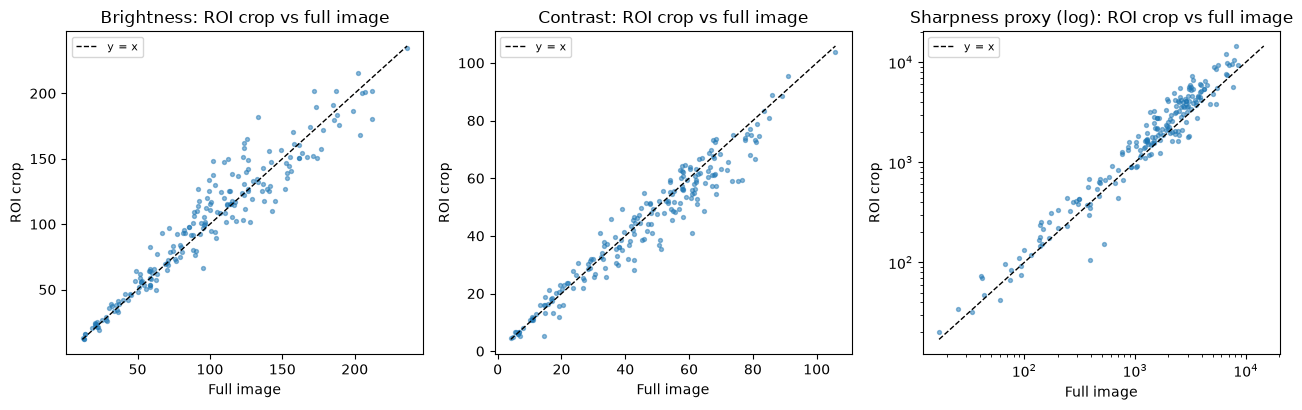

WindowsPath('C:/Users/Public/traffic-sign-audit/outputs/figures/fig08_roi_vs_full_image.png')

In [17]:
audit.plot_roi_vs_full(show=True)

## 7. Validation cell

In [18]:
checks = tsa.run_validation_checks(audit)
checks

{'missing_file_error_caught': True,
 'corrupt_image_error_caught': True,
 'feature_columns_exist': True,
 'review_flags_are_bool': True,
 'no_missing_core_features': True,
 'every_row_traceable_to_annotation': True}

## 8. Save tables and write the report

In [19]:
audit.save_tables()
print(write_report(audit))

C:\Users\Public\traffic-sign-audit\outputs\report.md
